<a href="https://colab.research.google.com/github/Rubin-S/nifty50-sma-backtester/blob/main/Dynamic_Volatility_Targeting_%26_Risk_Management.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantitative Strategy: Dynamic Volatility Targeting & Risk Management
## Module 1: Environment Setup, Data Ingestion & EWMA Volatility Engine

### Objective
Fetch daily data for the **NIFTY 50** (`^NSEI`) and compute 20-day Exponentially Weighted Moving Average (EWMA) annualized volatility to quantify real-time market risk:

$$\hat{\sigma}_t = \text{EWMA}_{\text{std}}(R_t, \text{span}=20) \times \sqrt{252}$$

In [1]:
# 1. Install & import dependencies
!pip install yfinance -q

import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt

# 2. Ingest NIFTY 50 daily historical data
ticker = "^NSEI"
df = yf.download(ticker, start="2018-01-01", auto_adjust=True)
if isinstance(df.columns, pd.MultiIndex):
    df.columns = df.columns.get_level_values(0)

# 3. Market returns & 20-day EWMA Realized Volatility
df['Market_Return'] = df['Close'].pct_change().fillna(0.0)
df['Realized_Vol'] = df['Market_Return'].ewm(span=20).std() * np.sqrt(252)

# 4. Display recent volatility estimates
df[['Close', 'Market_Return', 'Realized_Vol']].tail()

[*********************100%***********************]  1 of 1 completed


Price,Close,Market_Return,Realized_Vol
Date,,,
2026-08-21,24252.000000,0.000832,0.082748
2026-08-24,24219.050781,-0.001359,0.078907
2026-08-25,24334.550781,0.004769,0.078873
2026-08-26,24207.750000,-0.005211,0.079329
2026-08-27,24090.849609,-0.004829,0.078460


## Module 2: Dynamic Target Sizing & Leverage Capping

### Objective
Compute dynamic target weights using our annualized volatility target ($\sigma_{\text{target}} = 12\%$), enforce a cash-only leverage cap ($w_{\max} = 1.0$), and scale our trend-following signal:

$$w_t = \min\left(w_{\max}, \, \frac{\sigma_{\text{target}}}{\hat{\sigma}_t}\right)$$
$$\text{Target Position}_t = S_t \times w_t$$

In [2]:
# 1. Risk budget configuration
target_vol = 0.12       # 12% annualized target volatility
max_leverage = 1.0      # 1.0 = Cash-only cap (no borrowing)

# 2. Raw volatility target weight
df['Raw_Weight'] = target_vol / df['Realized_Vol']

# 3. Apply leverage cap
df['Capped_Weight'] = df['Raw_Weight'].clip(upper=max_leverage)

# 4. Compute 10/70 SMA trend signal (from our Project 2 optimization)
df['SMA_Fast'] = df['Close'].rolling(window=10).mean()
df['SMA_Slow'] = df['Close'].rolling(window=70).mean()
df['Raw_Signal'] = np.where(df['SMA_Fast'] > df['SMA_Slow'], 1.0, 0.0)

# 5. Unbuffered dynamic target position
df['Target_Position'] = df['Raw_Signal'] * df['Capped_Weight']

# 6. Inspect recent sizing calculations
df[['Close', 'Realized_Vol', 'Raw_Weight', 'Capped_Weight', 'Raw_Signal', 'Target_Position']].tail()

Price,Close,Realized_Vol,Raw_Weight,Capped_Weight,Raw_Signal,Target_Position
Date,,,,,,
2026-08-21,24252.000000,0.082748,1.450191,1.0,1.0,1.0
2026-08-24,24219.050781,0.078907,1.520780,1.0,1.0,1.0
2026-08-25,24334.550781,0.078873,1.521438,1.0,1.0,1.0
2026-08-26,24207.750000,0.079329,1.512691,1.0,1.0,1.0
2026-08-27,24090.849609,0.078460,1.529440,1.0,1.0,1.0


## Module 3: Tolerance Band (Rebalancing Buffer) & Execution Alignment

### Objective
Apply a $5\%$ rebalancing tolerance band to prevent turnover friction from minor daily volatility drift, and lag the execution by 1 day ($t+1$) to avoid look-ahead bias:

* **Buffer Rule:** Rebalance if $|\text{Target}_t - \text{Current}| \ge 0.05$ or when exiting to cash ($S_t = 0$).
* **Execution Lag:** $\text{Position}_t = \text{Buffered\_Target}_{t-1}$.

In [3]:
# 1. Define tolerance band threshold (5%)
buffer_threshold = 0.05

target_pos = df['Target_Position'].values
raw_signal = df['Raw_Signal'].values
buffered_pos = np.zeros(len(df))

# 2. Iterate to apply the tolerance band logic
current_pos = 0.0
for i in range(len(df)):
    if raw_signal[i] == 0.0:
        current_pos = 0.0
    elif abs(target_pos[i] - current_pos) >= buffer_threshold:
        current_pos = target_pos[i]
    buffered_pos[i] = current_pos

df['Buffered_Target'] = buffered_pos

# 3. Prevent look-ahead bias: shift by 1 day to execute at t+1
df['Position'] = df['Buffered_Target'].shift(1).fillna(0.0)

# 4. Inspect recent buffered targets and actual executed positions
df[['Close', 'Raw_Signal', 'Target_Position', 'Buffered_Target', 'Position']].tail()

Price,Close,Raw_Signal,Target_Position,Buffered_Target,Position
Date,,,,,
2026-08-21,24252.000000,1.0,1.0,1.0,1.0
2026-08-24,24219.050781,1.0,1.0,1.0,1.0
2026-08-25,24334.550781,1.0,1.0,1.0,1.0
2026-08-26,24207.750000,1.0,1.0,1.0,1.0
2026-08-27,24090.849609,1.0,1.0,1.0,1.0


## Module 4: Dynamic Strategy Returns & Friction Modeling

### Objective
Calculate daily portfolio returns based on dynamic position exposure and deduct transaction costs (5 bps) proportionally to rebalancing trade size:

$$\text{Trades}_t = |\text{Position}_t - \text{Position}_{t-1}|$$
$$R_{\text{strategy}, t} = (\text{Position}_t \times R_{\text{market}, t}) - (\text{Trades}_t \times \text{Cost})$$

In [4]:
# 1. Deduct proportional friction (5 bps = 0.05%)
fee_bps = 5
cost_per_trade = fee_bps / 10000.0

# 2. Compute trade turnover (proportional sizing)
df['Trades'] = df['Position'].diff().abs().fillna(0.0)

# 3. Dynamic Strategy Return
df['Strategy_Return'] = (df['Position'] * df['Market_Return']) - (df['Trades'] * cost_per_trade)

# 4. Compound Cumulative Equity Curves
df['Benchmark_Equity'] = (1 + df['Market_Return']).cumprod()
df['Strategy_Equity'] = (1 + df['Strategy_Return']).cumprod()

# 5. Inspect recent compounding
df[['Close', 'Position', 'Trades', 'Strategy_Return', 'Strategy_Equity']].tail()

Price,Close,Position,Trades,Strategy_Return,Strategy_Equity
Date,,,,,
2026-08-21,24252.000000,1.0,0.0,0.000832,1.884438
2026-08-24,24219.050781,1.0,0.0,-0.001359,1.881878
2026-08-25,24334.550781,1.0,0.0,0.004769,1.890852
2026-08-26,24207.750000,1.0,0.0,-0.005211,1.881000
2026-08-27,24090.849609,1.0,0.0,-0.004829,1.871916


## Module 5: Quantitative Performance & Risk Analytics

### Objective
Evaluate risk-adjusted performance metrics comparing the Volatility-Targeted Trend Strategy against the Buy & Hold benchmark:
* **CAGR:** Geometric annualized growth rate.
* **Annualized Volatility ($\sigma$):** Standard deviation of returns scaled by $\sqrt{252}$.
* **Sharpe Ratio:** Risk-adjusted return ($\frac{\text{CAGR}}{\sigma}$).
* **Max Drawdown (MDD):** Peak-to-trough capital decline.

In [5]:
# 1. Trading parameters
trading_days = 252
n_days = len(df)

# 2. Geometric CAGR
cagr_strat = (df['Strategy_Equity'].iloc[-1]) ** (trading_days / n_days) - 1
cagr_bench = (df['Benchmark_Equity'].iloc[-1]) ** (trading_days / n_days) - 1

# 3. Annualized Volatility
vol_strat = df['Strategy_Return'].std() * np.sqrt(trading_days)
vol_bench = df['Market_Return'].std() * np.sqrt(trading_days)

# 4. Sharpe Ratio (0% risk-free benchmark)
sharpe_strat = (cagr_strat / vol_strat) if vol_strat != 0 else 0.0
sharpe_bench = (cagr_bench / vol_bench) if vol_bench != 0 else 0.0

# 5. Maximum Drawdown (MDD)
rolling_max_strat = df['Strategy_Equity'].cummax()
dd_strat = (df['Strategy_Equity'] - rolling_max_strat) / rolling_max_strat
mdd_strat = dd_strat.min()

rolling_max_bench = df['Benchmark_Equity'].cummax()
dd_bench = (df['Benchmark_Equity'] - rolling_max_bench) / rolling_max_bench
mdd_bench = dd_bench.min()

# 6. Performance Summary Report
print("=== Dynamic Volatility Targeting: Performance Report ===")
print(f"Strategy CAGR:         {cagr_strat * 100:.2f}% | Benchmark: {cagr_bench * 100:.2f}%")
print(f"Annualized Volatility: {vol_strat * 100:.2f}% | Benchmark: {vol_bench * 100:.2f}%")
print(f"Sharpe Ratio:          {sharpe_strat:.2f}  | Benchmark: {sharpe_bench:.2f}")
print(f"Max Drawdown (MDD):    {mdd_strat * 100:.2f}% | Benchmark: {mdd_bench * 100:.2f}%")

=== Dynamic Volatility Targeting: Performance Report ===
Strategy CAGR:         7.69% | Benchmark: 10.38%
Annualized Volatility: 8.89% | Benchmark: 16.92%
Sharpe Ratio:          0.87  | Benchmark: 0.61
Max Drawdown (MDD):    -12.94% | Benchmark: -38.44%


## Module 6: Institutional Diagnostic Visualizations

### Objective
Render a 3-panel dashboard visualizing equity growth, rolling market volatility regimes relative to the target budget, and dynamic position exposure.

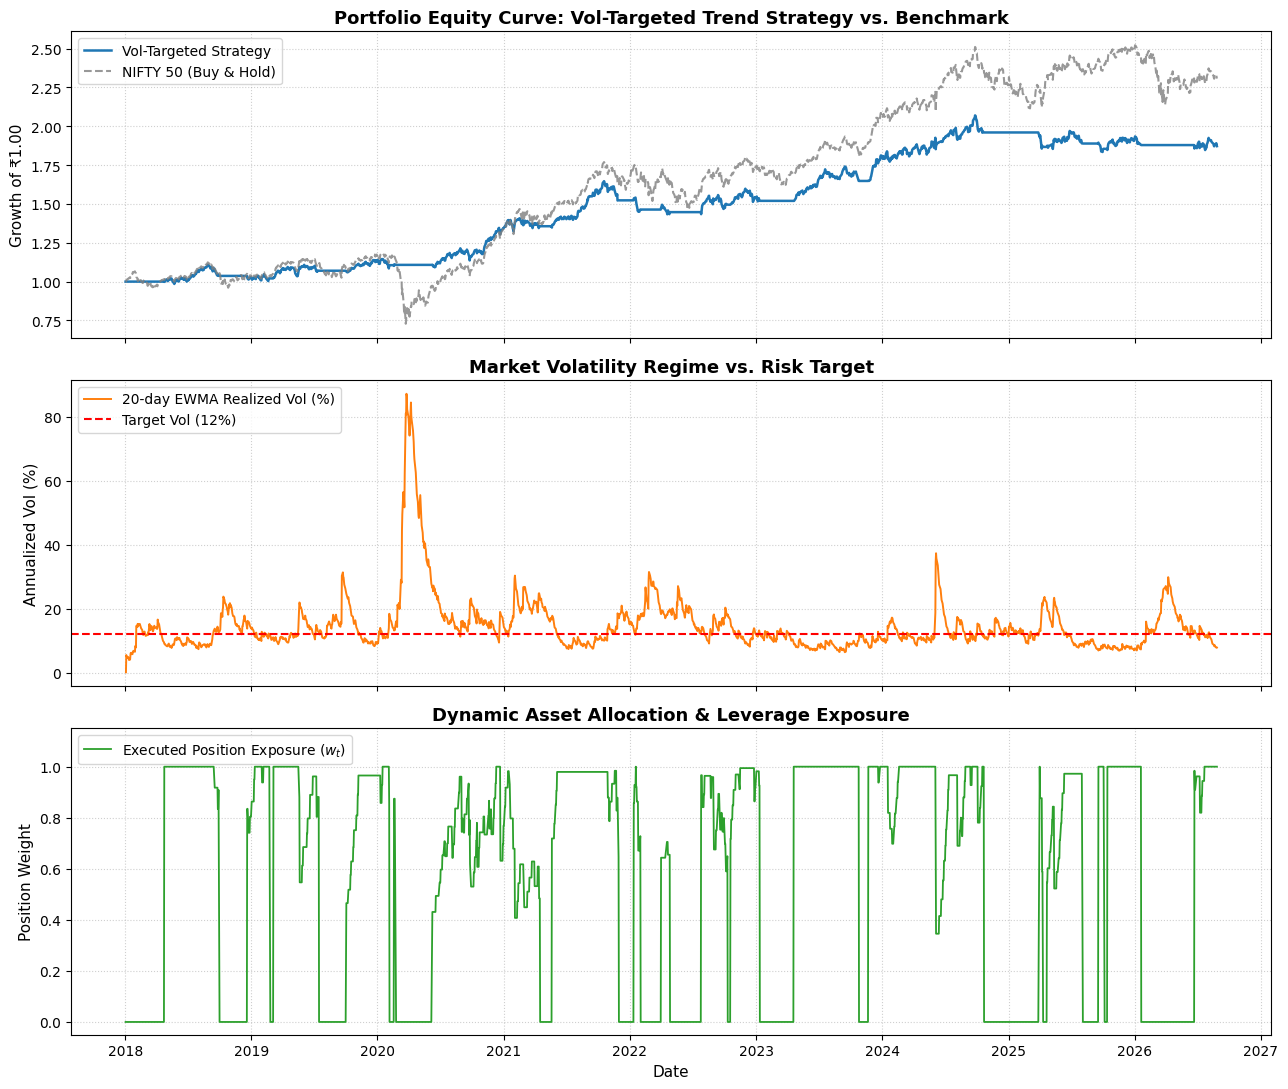

In [6]:
fig, axes = plt.subplots(3, 1, figsize=(13, 11), sharex=True)

# Panel 1: Compounded Equity Curves
axes[0].plot(df.index, df['Strategy_Equity'], label='Vol-Targeted Strategy', color='#1f77b4', linewidth=1.8)
axes[0].plot(df.index, df['Benchmark_Equity'], label='NIFTY 50 (Buy & Hold)', color='#7f7f7f', linestyle='--', alpha=0.8)
axes[0].set_title('Portfolio Equity Curve: Vol-Targeted Trend Strategy vs. Benchmark', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Growth of ₹1.00', fontsize=11)
axes[0].legend(loc='upper left')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Panel 2: Realized Volatility vs Target Budget
axes[1].plot(df.index, df['Realized_Vol'] * 100, label='20-day EWMA Realized Vol (%)', color='#ff7f0e', linewidth=1.4)
axes[1].axhline(target_vol * 100, color='red', linestyle='--', label=f'Target Vol ({target_vol*100:.0f}%)')
axes[1].set_title('Market Volatility Regime vs. Risk Target', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Annualized Vol (%)', fontsize=11)
axes[1].legend(loc='upper left')
axes[1].grid(True, linestyle=':', alpha=0.6)

# Panel 3: Dynamic Position Exposure
axes[2].plot(df.index, df['Position'], label='Executed Position Exposure ($w_t$)', color='#2ca02c', linewidth=1.3)
axes[2].set_title('Dynamic Asset Allocation & Leverage Exposure', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Position Weight', fontsize=11)
axes[2].set_xlabel('Date', fontsize=11)
axes[2].set_ylim(-0.05, 1.15)
axes[2].legend(loc='upper left')
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.savefig('nifty50_vol_targeting_dashboard.png', dpi=300, bbox_inches='tight')
plt.show()